Circuit execution successful!
Syndrome measurement counts (should see '01' due to X gate): {'01': 1000}


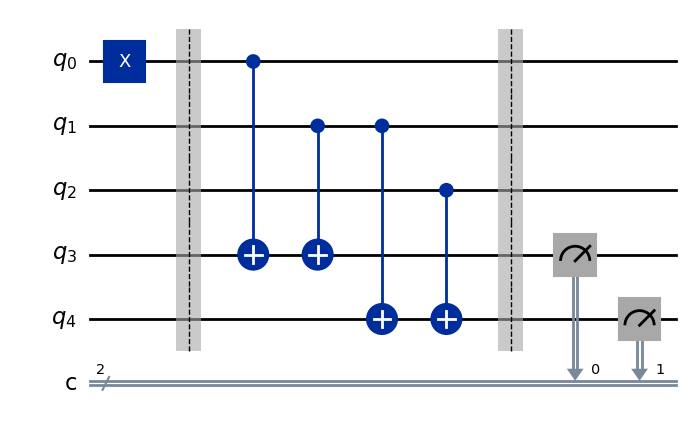

In [20]:
##### import qiskit
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

# 1. Initialize a 3-qubit repetition code circuit with 2 syndrome bits
# Qubits 0, 1, 2 are code qubits. Qubits 3, 4 are ancilla qubits.
circuit = QuantumCircuit(5, 2)

# 2. Insert bit flip fault (Flip qubit 0 to state |1>)
circuit.x(0)
circuit.barrier() #prevents compiler from removing injected fault

# 3. Entangle with ancillas to track potential phase or bit flips
circuit.cx(0, 3)
circuit.cx(1, 3)
circuit.cx(1, 4)
circuit.cx(2, 4)
circuit.barrier() #provides visible separation between entangle operations and readout

# 4. Measure the syndrome ancilla qubits into classical registers 0 and 1
circuit.measure(3, 0)
circuit.measure(4, 1)

# 5. Execute the circuit locally using Aer Simulator
simulator = AerSimulator()
compiled_circuit = qiskit.transpile(circuit, simulator) #compiles circuit into simulator-understood assembly
result = simulator.run(compiled_circuit, shots=1000).result()

# 6. Output the syndrome detection result
counts = result.get_counts()
print("Circuit execution successful!")
print("Syndrome measurement counts (should see '01' due to X gate):", counts)

# Render a clean, graphical circuit diagram
circuit.draw(output="mpl")

In [23]:
from qiskit.circuit import CircuitInstruction
from qiskit.circuit.library import XGate
from qiskit_qec.circuits.surface_code import SurfaceCodeCircuit

# 1. Initialize code and extract a specific logical circuit
code = SurfaceCodeCircuit(d=3, T=3, basis="z")
circuit = code.circuit["0"]

# 2. Pick target physical qubit index
# (For a d=3 surface code, data qubits are  indices 0 through 8)
target_qubit_index = 1
target_qubit = circuit.qubits[target_qubit_index]

# 3. Create fault gate instruction (an X gate)
fault_instruction = CircuitInstruction(XGate(), (target_qubit,))

# 4. Inject the fault into a specific location in the circuit
insertion_index = 10
circuit.data.insert(insertion_index, fault_instruction)

print(f"Successfully injected an X fault at circuit data index {insertion_index}!")
print(f"Total gate count is now: {len(circuit.data)}")

Successfully injected an X fault at circuit data index 10!
Total gate count is now: 146


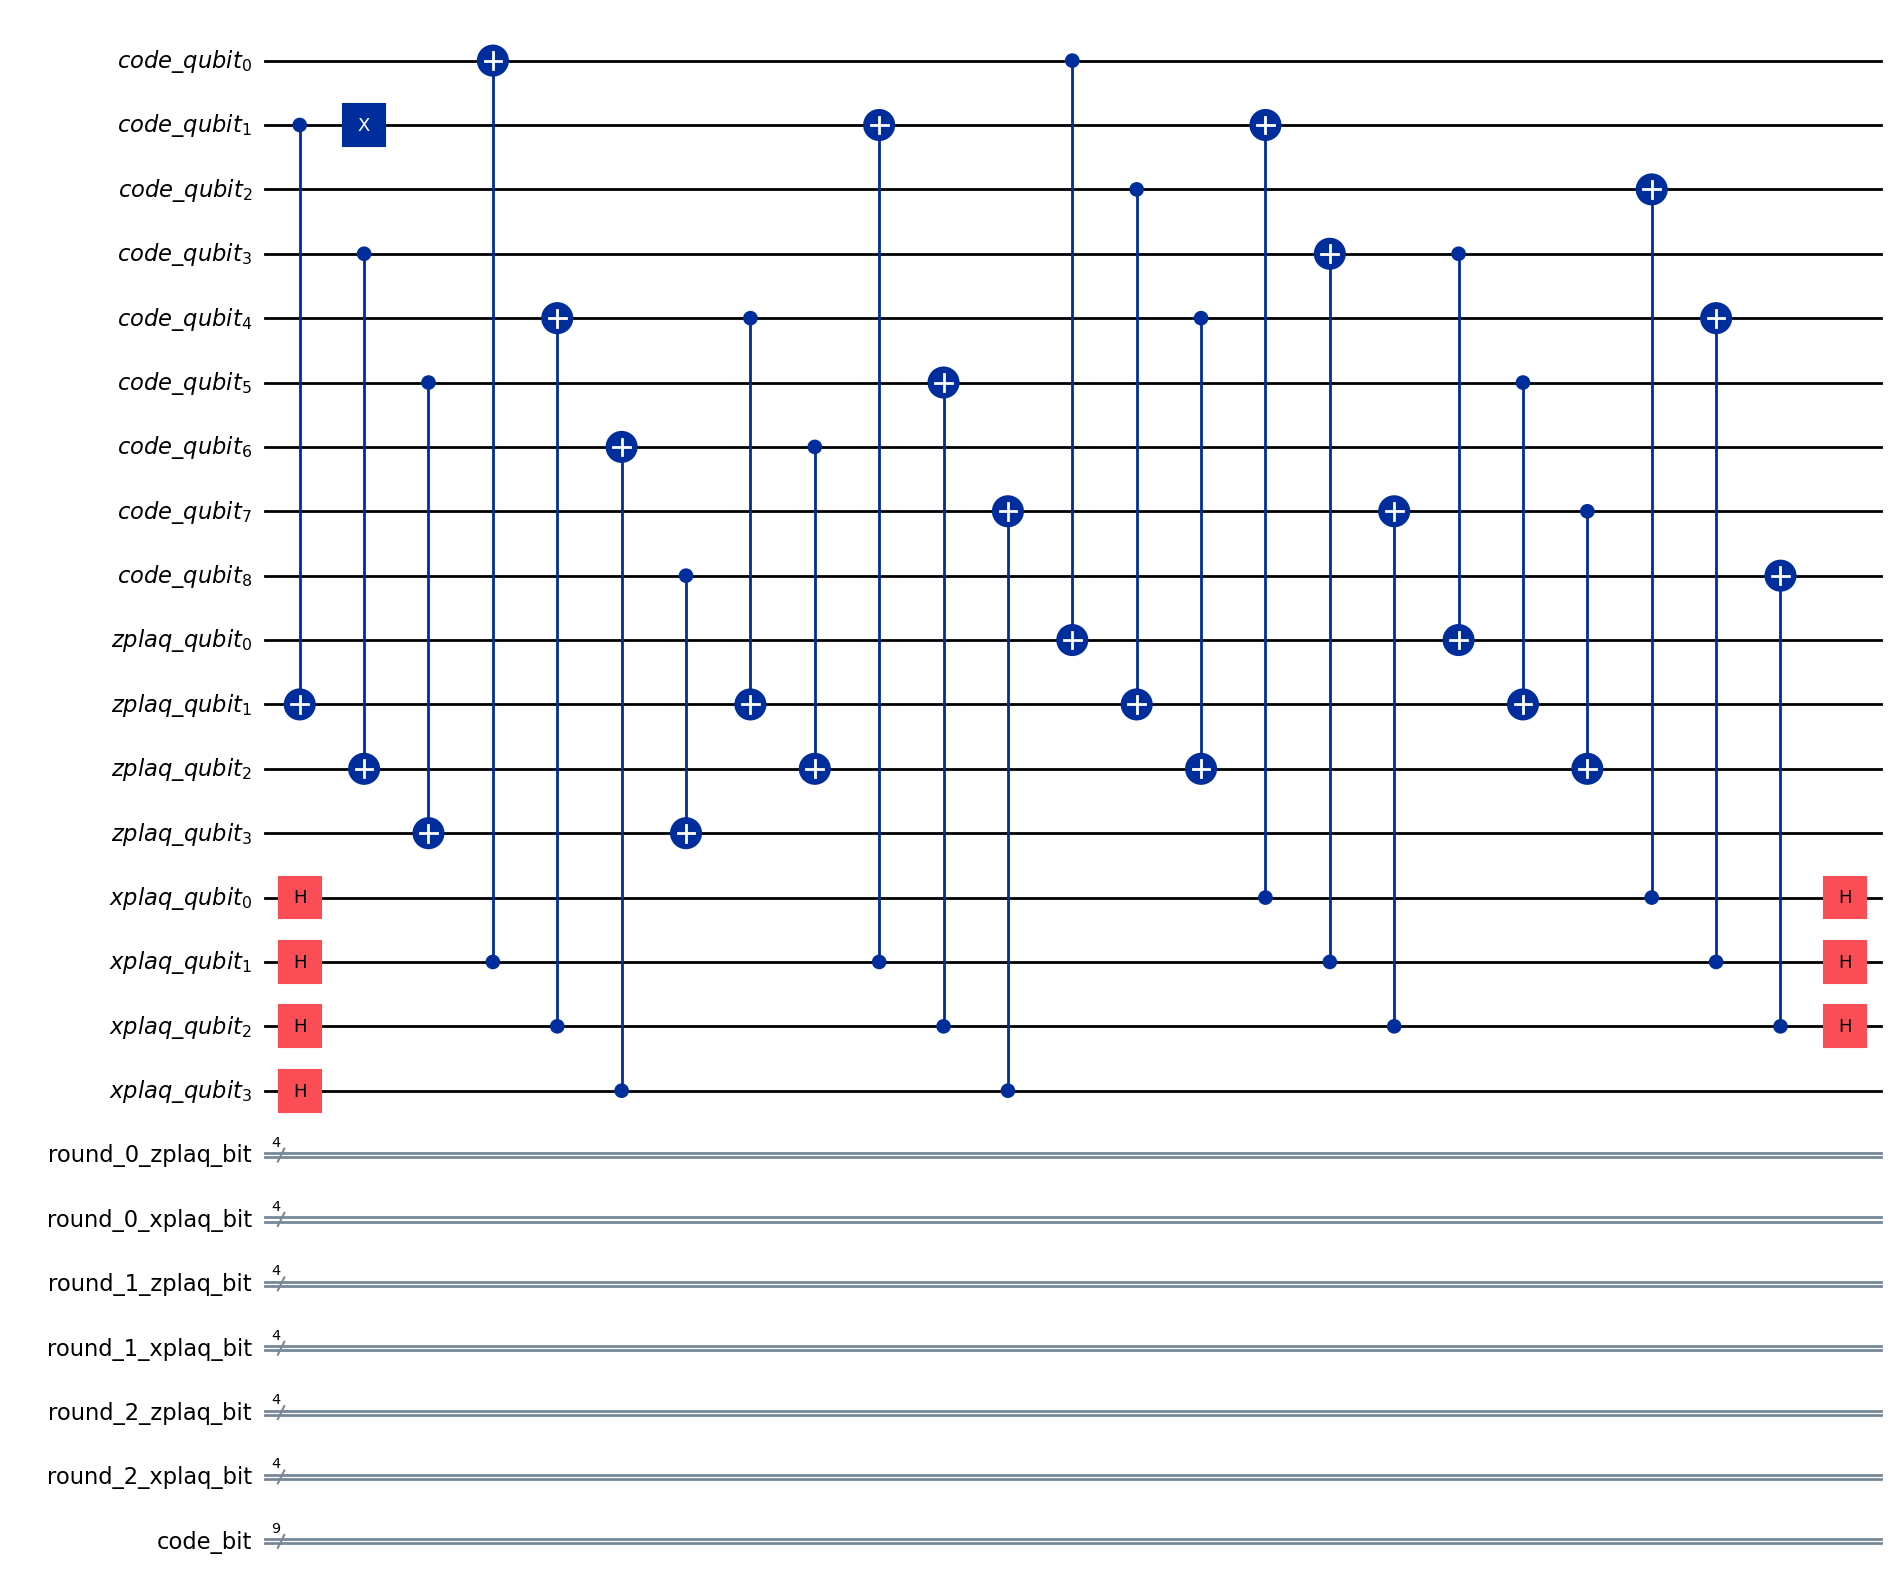

In [29]:
# Create a sub-circuit of the first 30 instructions to inspect closely
sub_circuit = circuit.copy()
sub_circuit.data = circuit.data[:32]
sub_circuit.draw(output="mpl")